# Zomato Restaurant Recommendation System (Content-Based, NLP)

**Goal:** the user types a restaurant name; the system looks at the *reviews* of all other restaurants, finds the ones whose reviews are most similar, and returns them **sorted from the highest rated**.

**Approach**
1. Load and clean the Zomato Bangalore data
2. Exploratory data analysis (EDA)
3. NLP pre-processing of the review text
4. TF-IDF vectorisation (one "document" per restaurant = all its reviews)
5. Cosine similarity between restaurants
6. Recommend: take the most similar restaurants, then sort by rating
7. Evaluate sanity of the recommendations
8. Save artifacts for the Streamlit app (`app.py`)

**Dataset:** Zomato Bangalore Restaurants (`zomato.csv`, from Kaggle). Place the file next to this notebook.

## 1. Imports and configuration

In [1]:
import re, ast, warnings
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from nltk.stem import PorterStemmer   # rule-based, needs no corpus download

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

RANDOM_STATE = 42
CANDIDATE_PATHS = [Path("zomato.csv"), Path("data/zomato.csv")]
DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)
assert DATA_PATH is not None, "zomato.csv not found - put it next to this notebook (or in ./data/)"
ARTIFACT_DIR = Path("artifacts"); ARTIFACT_DIR.mkdir(exist_ok=True)
print("Using data file:", DATA_PATH)

Using data file: zomato.csv


## 2. Load the data
We only load the columns we need (the file is ~570 MB, mostly the `reviews_list` text).

In [2]:
USE_COLS = ["name", "online_order", "book_table", "rate", "votes", "location", "rest_type",
            "dish_liked", "cuisines", "approx_cost(for two people)", "reviews_list",
            "listed_in(type)", "listed_in(city)", "url", "address", "phone"]
raw = pd.read_csv(DATA_PATH, usecols=USE_COLS)
print("Shape:", raw.shape)
raw.drop(columns="reviews_list").head()

Shape: (51717, 16)


,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banashankari?context=eyJzZSI6eyJlIjpb...,"942, 21st Main Road, 2nd Stage, Banashankari, Bangalore",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Lajawab, Tomato Shorba, Dum Biryan...","North Indian, Mughlai, Chinese",800,Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephant-banashankari?context=eyJzZSI...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th Block, Kathriguppe, 3rd Stage,...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai Green Curry, Paneer Tikka, Dum ...","Chinese, North Indian, Thai",800,Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?context=eyJzZSI6eyJlIjpbIjU4Njk0Ii...,"1112, Next to KIMS Medical College, 17th Cross, 2nd Stage, Banashankari, Ban...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Chocolate, Pink Sauce Pasta, Salsa...","Cafe, Mexican, Italian",800,Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi-bhojana-banashankari?context=...,"1st Floor, Annakuteera, 3rd Stage, Banashankari, Bangalore",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village-basavanagudi?context=eyJzZSI6...,"10, 3rd Floor, Lakshmi Associates, Gandhi Bazaar Main Road, Above Reliance T...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,Buffet,Banashankari


In [3]:
print("Duplicate rows:", raw.duplicated().sum())
print("Unique restaurant names:", raw["name"].nunique())
print("Unique (name, location) pairs:", raw.groupby(["name", "location"]).ngroups)
print("\nMissing values:")
raw.isna().sum()

Duplicate rows: 0
Unique restaurant names: 8792
Unique (name, location) pairs: 12140

Missing values:


url                                0
address                            0
name                               0
online_order                       0
book_table                         0
rate                            7775
votes                              0
phone                           1208
location                          21
rest_type                        227
dish_liked                     28078
cuisines                          45
approx_cost(for two people)      346
reviews_list                       0
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

**Observations**
- 51,717 rows but only ~12k unique restaurants: the same restaurant appears once per `listed_in(type)` category, so we must de-duplicate.
- `rate` is text like `"4.1/5"`, and has `NEW`, `-` and missing values.
- Chains (e.g. Domino's) exist in many locations, so the unique key is **name + location**.

## 3. Data cleaning

In [4]:
df = raw.rename(columns={"approx_cost(for two people)": "cost",
                         "listed_in(type)": "listed_type",
                         "listed_in(city)": "listed_city"}).copy()

# rate: "4.1/5", "3.9 /5" -> 4.1, 3.9 ; "NEW", "-" -> NaN
df["rate"] = df["rate"].astype(str).str.extract(r"(\d\.?\d*)\s*/\s*5")[0].astype(float)
# cost: "1,200" -> 1200
df["cost"] = pd.to_numeric(df["cost"].astype(str).str.replace(",", ""), errors="coerce")

df["location"] = df["location"].fillna("Unknown")
df["rest_type"] = df["rest_type"].fillna("Unknown")
df["cuisines"] = df["cuisines"].fillna("Unknown")
df["dish_liked"] = df["dish_liked"].fillna("")
df["url"] = df["url"].fillna("").str.split("?").str[0]                      # Zomato page without the long tracking suffix
df["address"] = df["address"].fillna("")
df["phone"] = df["phone"].fillna("").str.replace(r"\s*[\r\n]+\s*", ", ", regex=True).str.strip()

# one row per restaurant (name + location); drop those without rating or without reviews
df = df.drop_duplicates(subset=["name", "location"], keep="first")
df = df[df["rate"].notna() & (df["reviews_list"] != "[]")].reset_index(drop=True)
df["label"] = df["name"] + " - " + df["location"]       # unique, human readable id
assert df["label"].is_unique
print("Clean shape:", df.shape)
df.drop(columns="reviews_list").describe(include="all").T.head(12)

Clean shape: (8716, 17)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
url,8716,8674,https://www.zomato.com/bangalore/caf%C3%A9-felix-1-mg-road,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
address,8716,8120,Delivery Only,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,8716,6261,Cafe Coffee Day,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN
online_order,8716,2,Yes,5411,NaN,NaN,NaN,NaN,NaN,NaN,NaN
book_table,8716,2,No,7813,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rate,8716.0,NaN,NaN,NaN,3.638045,0.433002,1.8,3.4,3.7,3.9,4.9
votes,8716.0,NaN,NaN,NaN,251.545204,689.053286,0.0,18.0,57.0,201.25,16345.0
phone,8716,7850,,155,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,8716,90,Whitefield,544,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rest_type,8716,87,Quick Bites,3153,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Exploratory data analysis

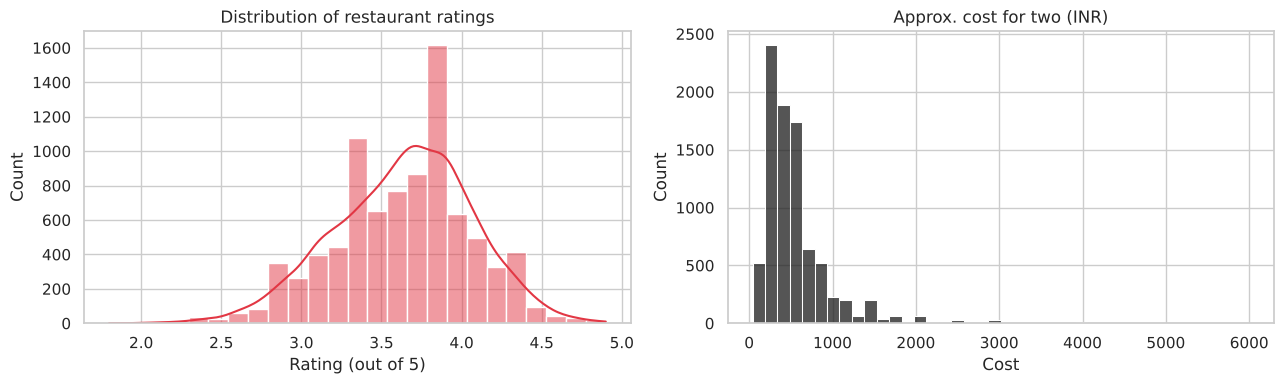

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["rate"], bins=25, kde=True, ax=ax[0], color="#E23744")
ax[0].set_title("Distribution of restaurant ratings"); ax[0].set_xlabel("Rating (out of 5)")
sns.histplot(df["cost"].dropna(), bins=40, ax=ax[1], color="#1C1C1C")
ax[1].set_title("Approx. cost for two (INR)"); ax[1].set_xlabel("Cost")
plt.tight_layout(); plt.show()

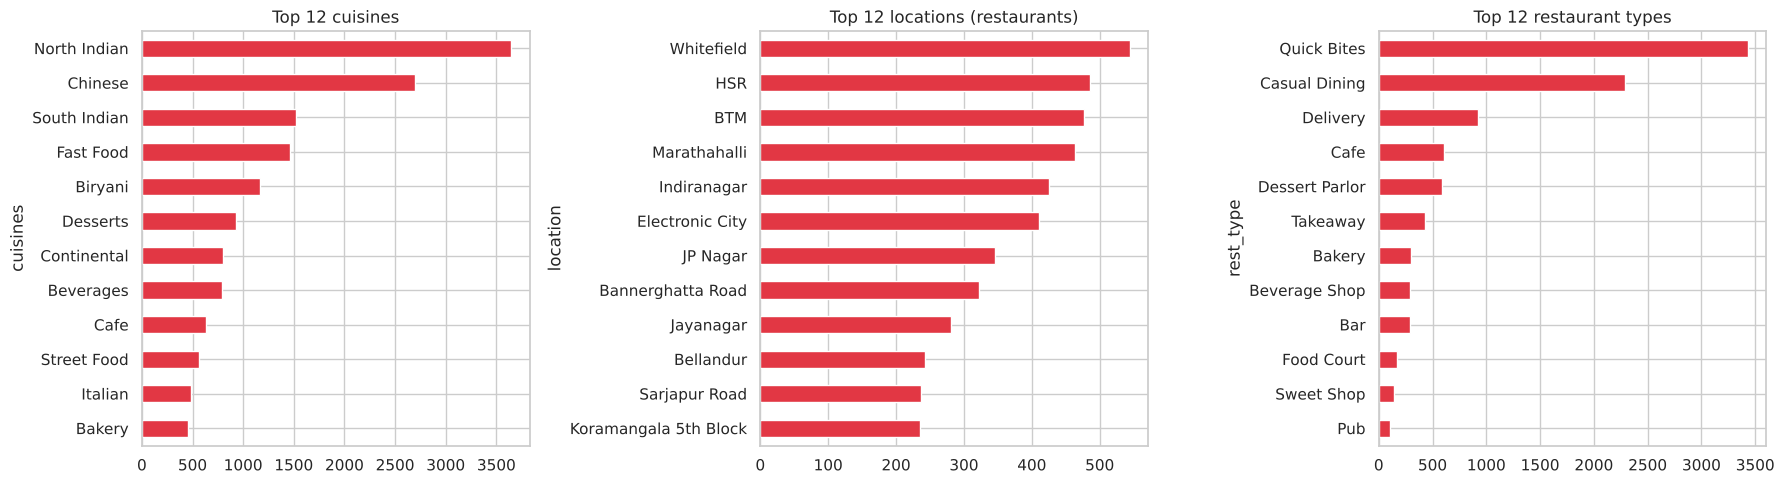

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
cuis = df["cuisines"].str.split(",").explode().str.strip()
cuis[cuis != "Unknown"].value_counts().head(12).sort_values().plot.barh(ax=ax[0], color="#E23744")
ax[0].set_title("Top 12 cuisines")
df["location"].value_counts().head(12).sort_values().plot.barh(ax=ax[1], color="#E23744")
ax[1].set_title("Top 12 locations (restaurants)")
df["rest_type"].str.split(",").explode().str.strip().value_counts().head(12).sort_values().plot.barh(ax=ax[2], color="#E23744")
ax[2].set_title("Top 12 restaurant types")
plt.tight_layout(); plt.show()

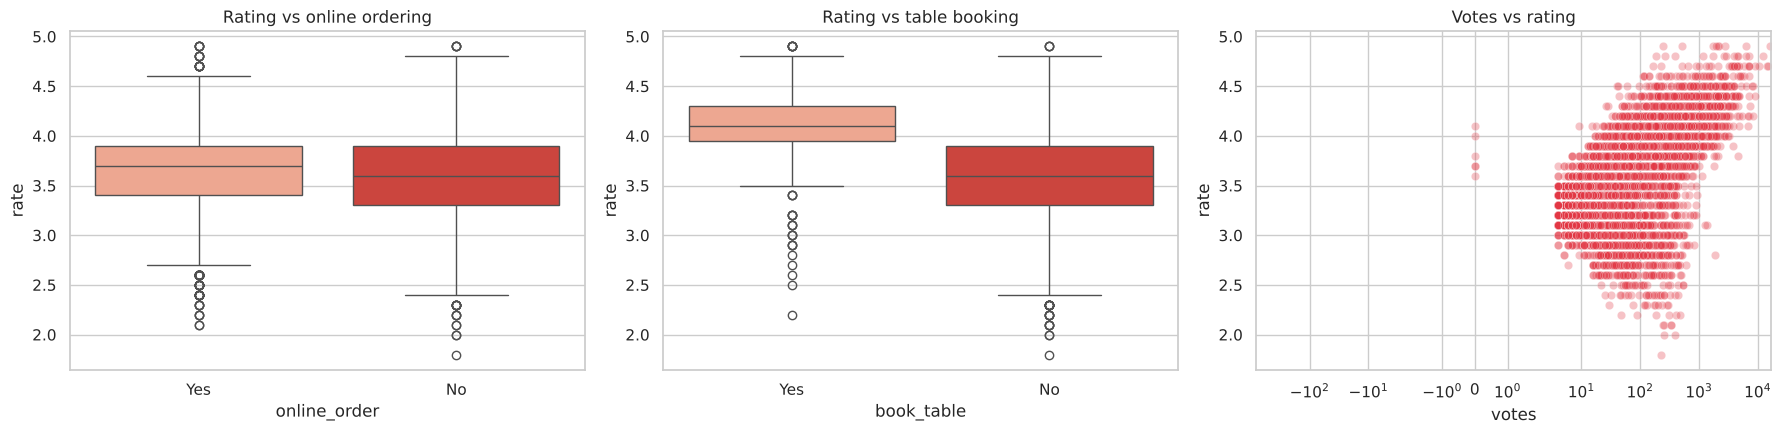

           count  mean
cost                  
<300        2928  3.56
300-500     2813  3.56
500-800     1824  3.66
800-1200     583  3.87
1200-2000    433  4.14
2000+        104  4.15


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
sns.boxplot(data=df, x="online_order", y="rate", ax=ax[0], palette="Reds"); ax[0].set_title("Rating vs online ordering")
sns.boxplot(data=df, x="book_table", y="rate", ax=ax[1], palette="Reds"); ax[1].set_title("Rating vs table booking")
sns.scatterplot(data=df, x="votes", y="rate", alpha=.3, ax=ax[2], color="#E23744")
ax[2].set_xscale("symlog"); ax[2].set_title("Votes vs rating")
plt.tight_layout(); plt.show()

bins = pd.cut(df["cost"], [0, 300, 500, 800, 1200, 2000, 10000], labels=["<300", "300-500", "500-800", "800-1200", "1200-2000", "2000+"])
print(df.groupby(bins, observed=True)["rate"].agg(["count", "mean"]).round(2))

**EDA takeaways** – ratings centre around 3.5-4.0; North Indian, Chinese and Fast Food dominate; restaurants accepting table bookings and higher-cost places tend to be rated higher; very high ratings usually come with many votes. These columns are used later for **filters** in the app, while the **similarity itself comes only from review text**.

## 5. NLP pre-processing of the reviews

`reviews_list` is a string that looks like a Python list of `(rating, review_text)` tuples. For each restaurant we
1. parse the string and join all review texts into **one document**,
2. fix the broken-encoding characters, lower-case, remove URLs, digits and punctuation,
3. remove stop-words (scikit-learn list + a few domain words such as *rated*, *zomato*),
4. stem each word (Porter stemmer) so *tasty / tastes / taste* map to one token.

In [8]:
def parse_reviews(raw_str):
    # Return list of review texts from the raw `reviews_list` string.
    try:
        items = ast.literal_eval(raw_str)
        texts = [str(t) for _, t in items]
    except Exception:                      # fallback if a row is malformed
        texts = re.split(r"\('Rated [\d.]+', 'RATED", raw_str)
    out = []
    for t in texts:
        t = t.replace("\\n", " ").replace("\n", " ")
        t = re.sub(r"^\s*RATED\s*", "", t).strip()
        t = t.encode("ascii", "ignore").decode()          # drop mojibake like 'Ã\x83'
        if t:
            out.append(t)
    return out

df["review_texts"] = df["reviews_list"].map(parse_reviews)
df["n_reviews"] = df["review_texts"].map(len)
df = df[df["n_reviews"] > 0].reset_index(drop=True)
print("Restaurants:", len(df), "| avg reviews per restaurant:", round(df["n_reviews"].mean(), 1))
df.loc[0, "review_texts"][:2]

Restaurants: 8716 | avg reviews per restaurant: 25.8


['A beautiful place to dine in.The interiors take you back to the Mughal era. The lightings are just perfect.We went there on the occasion of Christmas and so they had only limited items available. But the taste and service was not compromised at all.The only complaint is that the breads could have been better.Would surely like to come here again.',
 'I was here for dinner with my family on a weekday. The restaurant was completely empty. Ambience is good with some good old hindi music. Seating arrangement are good too. We ordered masala papad, panner and baby corn starters, lemon and corrionder soup, butter roti, olive and chilli paratha. Food was fresh and good, service is good too. Good for family hangout. Cheers']

In [9]:
# The cleaning code lives in text_utils.py so the Streamlit app applies EXACTLY the same steps to user input
from text_utils import clean_text, build_unstem, STOP, DOMAIN_STOP
import inspect
print(inspect.getsource(clean_text))

sample = df.loc[0, "review_texts"][0]
print("BEFORE:", sample[:250]); print("AFTER :", clean_text(sample)[:250])

def clean_text(text):
    """Full pipeline used for the model: tokens + Porter stemming."""
    return " ".join(stem(w) for w in tokens(text))

BEFORE: A beautiful place to dine in.The interiors take you back to the Mughal era. The lightings are just perfect.We went there on the occasion of Christmas and so they had only limited items available. But the taste and service was not compromised at all.T
AFTER : beauti dine interior mughal era light perfect occas christma limit item avail tast servic compromis complaint bread better sure come


count     8716.0
mean       561.0
std       1452.0
min          0.0
25%         45.0
50%        107.0
75%        308.0
max      29970.0
Name: doc_len, dtype: float64


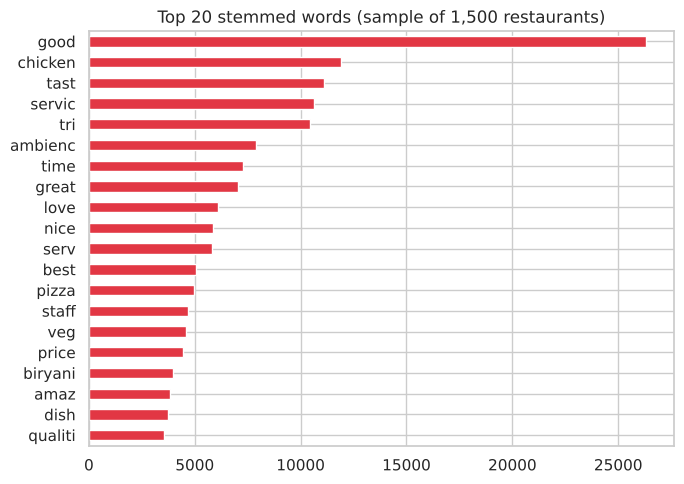

In [10]:
df["doc"] = df["review_texts"].map(lambda texts: clean_text(" ".join(texts)))
df["doc_len"] = df["doc"].str.split().str.len()
print(df["doc_len"].describe().round(0))

# most frequent words across all documents
from collections import Counter
cnt = Counter()
for d in df["doc"].sample(1500, random_state=RANDOM_STATE):
    cnt.update(d.split())
top = pd.Series(dict(cnt.most_common(20))).sort_values()
top.plot.barh(figsize=(7, 5), color="#E23744", title="Top 20 stemmed words (sample of 1,500 restaurants)")
plt.tight_layout(); plt.show()

## 6. TF-IDF vectorisation and cosine similarity

- **TF-IDF** gives high weight to words that are frequent in one restaurant's reviews but rare overall (e.g. *biryani*, *rooftop*, *brewery*), and low weight to generic words.
- Unigrams + bigrams (`ngram_range=(1,2)`) capture phrases such as *live music* or *butter chicken*.
- Rows are L2-normalised, so **cosine similarity = dot product**.

In [11]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.5, max_features=20000,
                        sublinear_tf=True, dtype=np.float32)
X = tfidf.fit_transform(df["doc"])
print("TF-IDF matrix:", X.shape, "| non-zeros:", X.nnz)
terms = np.array(tfidf.get_feature_names_out())
def top_terms(i, k=10):
    row = X[i].toarray().ravel()
    return list(terms[row.argsort()[::-1][:k]])
for i in [0, 1, 2]:
    print(df.loc[i, "label"], "->", top_terms(i))

TF-IDF matrix: (8716, 20000) | non-zeros: 1844441
Jalsa - Banashankari -> ['good standard', 'trademark', 'nice comfort', 'soya chaap', 'chaap', 'basement', 'standout', 'steep', 'buffet', 'maintain good']
Spice Elephant - Banashankari -> ['wafer', 'buffet', 'littl expens', 'good littl', 'leg', 'chocol cake', 'kurchan', 'biriyani good', 'quantiti serv', 'famili']
San Churro Cafe - Banashankari -> ['churro', 'san', 'bakasura', 'nacho', 'load nacho', 'pizza', 'cafe', 'cockroach', 'chocol sauc', 'banashankari']


Computing the full 9k x 9k similarity matrix is cheap, but saving it would be large. Instead we compute it in chunks and keep only the **top-K nearest neighbours per restaurant** (indices + similarity scores). This is tiny on disk and lets the app respond instantly.

In [12]:
K = 300
n = X.shape[0]
nb_idx = np.zeros((n, K), dtype=np.int32)
nb_sim = np.zeros((n, K), dtype=np.float32)
CHUNK = 1000
for start in range(0, n, CHUNK):
    end = min(start + CHUNK, n)
    S = (X[start:end] @ X.T).toarray()                    # (chunk, n) cosine similarities
    S[np.arange(end - start), np.arange(start, end)] = -1  # exclude the restaurant itself
    part = np.argpartition(-S, K, axis=1)[:, :K]
    order = np.take_along_axis(S, part, 1).argsort(axis=1)[:, ::-1]
    top = np.take_along_axis(part, order, 1)
    nb_idx[start:end] = top
    nb_sim[start:end] = np.take_along_axis(S, top, 1)
print("neighbour arrays:", nb_idx.shape, nb_sim.shape, "| mean top-1 similarity:", nb_sim[:, 0].mean().round(3))

neighbour arrays: (8716, 300) (8716, 300) | mean top-1 similarity: 0.231


## 7. The recommender

**Logic**
1. Find the input restaurant.
2. Take the `pool` most similar restaurants by review text (default 50), after applying optional filters (location, cuisine, max cost, min rating) and, by default, removing other branches of the same chain.
3. **Sort that pool by rating (highest first)**, using votes as the tie-breaker, and return the top *N*.

Step 2 keeps the results relevant; step 3 gives the "highest rated first" ordering requested in the problem statement.

In [13]:
label_to_idx = {l: i for i, l in enumerate(df["label"])}

def search_restaurants(query, limit=15):
    # Case-insensitive partial match on restaurant name -> list of labels.
    q = query.strip().lower()
    return df.loc[df["name"].str.lower().str.contains(q, regex=False), "label"].head(limit).tolist()

def recommend(label, top_n=10, pool=50, min_rating=0.0, max_cost=None, location=None, cuisine=None,
              exclude_same_brand=True):
    if label not in label_to_idx:
        raise KeyError(f"'{label}' not found. Try search_restaurants('{label.split(' - ')[0]}')")
    i = label_to_idx[label]
    cand = df.iloc[nb_idx[i]][["label", "name", "location", "cuisines", "rest_type", "rate", "votes", "cost"]].copy()
    cand["similarity"] = nb_sim[i]
    mask = cand["rate"] >= min_rating
    if exclude_same_brand: mask &= cand["name"] != df.at[i, "name"]   # skip other branches of the same chain
    if max_cost:  mask &= cand["cost"].isna() | (cand["cost"] <= max_cost)
    if location:  mask &= cand["location"].isin(location if isinstance(location, (list, set, tuple)) else [location])
    if cuisine:   mask &= cand["cuisines"].str.contains("|".join(map(re.escape, cuisine if isinstance(cuisine, (list, set, tuple)) else [cuisine])), case=False)
    cand = cand[mask].head(pool)                                     # most similar first
    cand = cand.sort_values(["rate", "votes"], ascending=False).head(top_n)  # then best rated first
    return cand.reset_index(drop=True)

print(df.loc[label_to_idx[search_restaurants("Jalsa")[0]], ["label", "cuisines", "rate"]].to_dict())
recommend(search_restaurants("Jalsa")[0], top_n=10)

{'label': 'Jalsa - Banashankari', 'cuisines': 'North Indian, Mughlai, Chinese', 'rate': 4.1}


,label,name,location,cuisines,rest_type,rate,votes,cost,similarity
0,Punjab Grill - Malleshwaram,Punjab Grill,Malleshwaram,"North Indian, Mughlai",Casual Dining,4.9,1940,2000.0,0.119275
1,Koramangala Social - Koramangala 7th Block,Koramangala Social,Koramangala 7th Block,"American, North Indian, Chinese, Finger Food",Lounge,4.6,4650,1500.0,0.119419
2,Sultans of Spice - Koramangala 5th Block,Sultans of Spice,Koramangala 5th Block,"North Indian, Mughlai, Salad",Casual Dining,4.5,3458,1300.0,0.143433
3,Jalsa Gold - Marathahalli,Jalsa Gold,Marathahalli,"North Indian, Mughlai, Italian",Casual Dining,4.5,3421,1300.0,0.189806
4,The Pallet - Whitefield,The Pallet,Whitefield,"Continental, Mediterranean, Italian, North Indian, Finger Food, Asian, Momos","Microbrewery, Pub",4.5,2745,1600.0,0.119011
5,Mainland China - Malleshwaram,Mainland China,Malleshwaram,Chinese,Casual Dining,4.5,1150,1700.0,0.118828
6,Deja Vu Resto Bar - Bannerghatta Road,Deja Vu Resto Bar,Bannerghatta Road,"North Indian, Italian",Pub,4.4,2487,900.0,0.122895
7,XOOX Brewmill - Koramangala 5th Block,XOOX Brewmill,Koramangala 5th Block,"Modern Indian, European, Asian","Microbrewery, Casual Dining",4.4,1533,2000.0,0.121226
8,Cable Car - Jayanagar,Cable Car,Jayanagar,"North Indian, Italian",Casual Dining,4.4,1224,1000.0,0.137555
9,Dhaba Estd 1986 Delhi - Marathahalli,Dhaba Estd 1986 Delhi,Marathahalli,North Indian,"Casual Dining, Bar",4.4,1209,1100.0,0.143262


In [14]:
for q in ["Truffles", "Empire Restaurant", "Onesta"]:
    hits = search_restaurants(q)
    if hits:
        print(f"\n=== Because you liked: {hits[0]}  ({df.loc[label_to_idx[hits[0]], 'cuisines']}) ===")
        display(recommend(hits[0], top_n=6)[["name", "location", "cuisines", "rate", "votes", "similarity"]])


=== Because you liked: Truffles - St. Marks Road  (Cafe, American, Burger, Steak) ===


,name,location,cuisines,rate,votes,similarity
0,The Pizza Bakery,Indiranagar,"Italian, Pizza, Beverages",4.8,1724,0.187341
1,Toit,Indiranagar,"Italian, American, Pizza",4.7,14956,0.190062
2,Biergarten,Whitefield,"Continental, European, BBQ, Chinese, Asian",4.7,6865,0.184810
3,Brew and Barbeque - A Microbrewery Pub,Marathahalli,"Continental, North Indian, BBQ, Steak",4.7,5746,0.183105
4,Chianti,Indiranagar,Italian,4.7,4398,0.188959
5,ECHOES Koramangala,Koramangala 5th Block,"Chinese, American, Continental, Italian, North Indian",4.7,3197,0.208206



=== Because you liked: Empire Restaurant - Jayanagar  (North Indian, Mughlai, South Indian, Chinese) ===


,name,location,cuisines,rate,votes,similarity
0,The Black Pearl,Marathahalli,"North Indian, European, Mediterranean, BBQ",4.8,7023,0.165351
1,Roots,Koramangala 1st Block,"North Indian, South Indian, Chinese, Continental, Mangalorean",4.5,1877,0.160829
2,Karama Restaurant,Frazer Town,"Arabian, North Indian, Beverages",4.4,2860,0.177607
3,Nagarjuna,Koramangala 5th Block,"Andhra, North Indian, Biryani",4.3,2296,0.160227
4,Sharief Bhai,Koramangala 5th Block,"Mughlai, Biryani",4.3,1520,0.164537
5,The Hidden Home,Sarjapur Road,"Asian, Chinese, Continental, North Indian, South Indian",4.3,994,0.173441



=== Because you liked: Onesta - Banashankari  (Pizza, Cafe, Italian) ===


,name,location,cuisines,rate,votes,similarity
0,The Pizza Bakery,Indiranagar,"Italian, Pizza, Beverages",4.8,1724,0.170728
1,Big Pitcher,Old Airport Road,"American, Continental, North Indian, Mediterranean",4.7,9021,0.162584
2,Biergarten,Whitefield,"Continental, European, BBQ, Chinese, Asian",4.7,6865,0.151736
3,Brew and Barbeque - A Microbrewery Pub,Marathahalli,"Continental, North Indian, BBQ, Steak",4.7,5746,0.155136
4,Hammered,Cunningham Road,"North Indian, Thai, Japanese, Continental, Cafe",4.7,4639,0.143134
5,Koramangala Social,Koramangala 7th Block,"American, North Indian, Chinese, Finger Food",4.6,4650,0.140868


In [15]:
# Example with filters: similar to Jalsa, but only well-rated and affordable
recommend(search_restaurants("Jalsa")[0], top_n=8, min_rating=4.0, max_cost=1000)[["name", "location", "cuisines", "rate", "cost", "similarity"]]

,name,location,cuisines,rate,cost,similarity
0,House Of Commons,Koramangala 5th Block,"Continental, Asian, North Indian",4.8,1000.0,0.107736
1,Bologna,Indiranagar,Italian,4.5,1000.0,0.107400
2,Onesta,HSR,"Pizza, Cafe, Italian",4.4,600.0,0.102211
3,Deja Vu Resto Bar,Bannerghatta Road,"North Indian, Italian",4.4,900.0,0.122895
4,Yo! Chow,Marathahalli,"Chinese, Momos",4.4,800.0,0.101186
5,Cable Car,Jayanagar,"North Indian, Italian",4.4,1000.0,0.137555
6,Gramin,Koramangala 7th Block,North Indian,4.3,600.0,0.112422
7,Food Ras,Electronic City,"North Indian, Chinese, Japanese, European, Seafood",4.3,900.0,0.100962


### 7b. Search by description (free text)

The same TF-IDF model also answers a free-text request such as *"romantic rooftop with live music"*: the text is cleaned with the same pipeline, converted to a TF-IDF vector and compared with every restaurant. The Streamlit app uses this for its **Describe what you want** tab.

In [16]:
def search_by_description(query, top_n=8, pool=50, min_rating=0.0):
    q = tfidf.transform([clean_text(query)])
    if q.nnz == 0:
        return pd.DataFrame()                       # none of the words are in the vocabulary
    sims = (X @ q.T).toarray().ravel()
    top = np.argsort(-sims)[:pool]
    cand = df.iloc[top][["name", "location", "cuisines", "rate", "votes"]].copy()
    cand["similarity"] = sims[top]
    cand = cand[(cand["rate"] >= min_rating) & (cand["similarity"] > 0)]
    return cand.sort_values(["rate", "votes"], ascending=False).head(top_n).reset_index(drop=True)

for q in ["romantic rooftop with live music", "cheap and tasty biryani", "good place for kids birthday party"]:
    print(f"\n>>> {q}")
    display(search_by_description(q, top_n=5))


>>> romantic rooftop with live music


,name,location,cuisines,rate,votes,similarity
0,Opus Food Stories,Sarjapur Road,"Goan, Asian, North Indian, European, Continental",4.7,163,0.087372
1,The Terrace at Gilly's Redefined,Koramangala 4th Block,"Continental, Finger Food, Asian, North Indian",4.6,866,0.110927
2,Hakuna Matata,JP Nagar,"North Indian, Asian, Seafood, Chinese",4.5,2781,0.087411
3,"3B's - Buddies, Bar & Barbecues",Marathahalli,"North Indian, Mediterranean, European, BBQ",4.5,1909,0.119689
4,Toscano,Lavelle Road,"Italian, Salad",4.4,1840,0.086950



>>> cheap and tasty biryani


,name,location,cuisines,rate,votes,similarity
0,Biryani Kitchen,Whitefield,Biryani,4.3,627,0.074862
1,Al-Bek,Malleshwaram,"Mughlai, Chinese",4.1,935,0.076316
2,The Purple Pan,Rajajinagar,"North Indian, Chinese",4.1,500,0.084365
3,Paradise,New BEL Road,"Biryani, North Indian, Kebab",4.0,1586,0.081869
4,Mani's Dum Biryani,Jeevan Bhima Nagar,"Biryani, Kebab",4.0,682,0.080108



>>> good place for kids birthday party


,name,location,cuisines,rate,votes,similarity
0,Barbecue by Punjab Grill,Malleshwaram,BBQ,4.7,1316,0.093431
1,Corner House Ice Cream,Seshadripuram,"Ice Cream, Desserts",4.4,402,0.095521
2,The Meal Story,Sarjapur Road,"North Indian, Street Food",4.2,258,0.127039
3,Bistro Claytopia,Koramangala 1st Block,"Cafe, American, Italian, Burger",4.1,1845,0.093204
4,Divina - Eden Park Restaurants,Jayanagar,Desserts,4.0,147,0.161034


## 8. Evaluation

There are no user-click labels, so we use a proxy: **cuisine overlap (Jaccard)** between the query restaurant and its recommendations. Cuisines were *not* used to build the model, so higher overlap than a random baseline shows that review text alone captures what a restaurant serves.

Random restaurants          0.104
Our recommender (top-10)    0.409
Our recommender (top-1)     0.467
dtype: float64


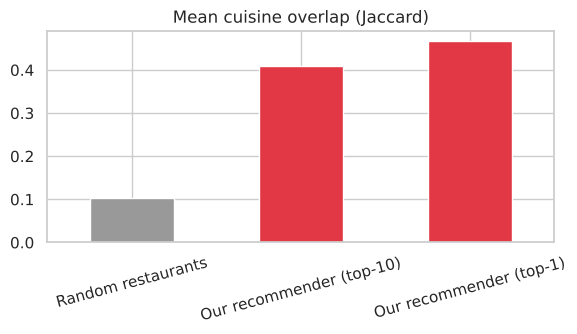

In [17]:
rng = np.random.default_rng(RANDOM_STATE)
cuisine_sets = df["cuisines"].map(lambda s: {c.strip().lower() for c in s.split(",")})
def jaccard(a, b): return len(a & b) / len(a | b) if (a | b) else 0

sample_idx = rng.choice(n, 400, replace=False)
model_scores, random_scores, top1_scores = [], [], []
for i in sample_idx:
    rec_idx = nb_idx[i][:10]
    model_scores.append(np.mean([jaccard(cuisine_sets[i], cuisine_sets[j]) for j in rec_idx]))
    top1_scores.append(jaccard(cuisine_sets[i], cuisine_sets[nb_idx[i][0]]))
    rand_idx = rng.choice(n, 10, replace=False)
    random_scores.append(np.mean([jaccard(cuisine_sets[i], cuisine_sets[j]) for j in rand_idx]))

res = pd.Series({"Random restaurants": np.mean(random_scores),
                 "Our recommender (top-10)": np.mean(model_scores),
                 "Our recommender (top-1)": np.mean(top1_scores)}).round(3)
print(res)
res.plot.bar(color=["#999999", "#E23744", "#E23744"], figsize=(6, 3.5), title="Mean cuisine overlap (Jaccard)")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

## 9. Save artifacts for the Streamlit app
Besides the neighbour index and restaurant table, we also save the TF-IDF vectorizer, the TF-IDF matrix, a stem-to-word map (to show readable phrases) and approximate area coordinates (for the map).

In [18]:
import joblib
app_cols = ["label", "name", "location", "cuisines", "rest_type", "rate", "votes", "cost",
            "online_order", "book_table", "dish_liked", "n_reviews", "url", "address", "phone"]
app_df = df[app_cols].copy()
app_df["top_review"] = df["review_texts"].map(lambda ts: next((t for t in ts if len(t) >= 60), ts[0])[:300])

from geo import LOCATION_COORDS          # approximate neighbourhood centres (dataset has no coordinates)
app_df["lat"] = app_df["location"].map(lambda l: LOCATION_COORDS.get(l, (np.nan, np.nan))[0])
app_df["lon"] = app_df["location"].map(lambda l: LOCATION_COORDS.get(l, (np.nan, np.nan))[1])
app_df.to_pickle(ARTIFACT_DIR / "restaurants.pkl")
np.savez_compressed(ARTIFACT_DIR / "neighbors.npz", idx=nb_idx, sim=nb_sim)

# extra files for the live-demo features: free-text search, "why recommended" and readable terms
import json
tfidf.stop_words_ = None                                  # not needed at prediction time; keeps the file small
joblib.dump(tfidf, ARTIFACT_DIR / "tfidf.joblib", compress=3)
sp.save_npz(ARTIFACT_DIR / "tfidf_matrix.npz", X.tocsr())
unstem = build_unstem(df["review_texts"].sample(3000, random_state=RANDOM_STATE).map(" ".join))
json.dump(unstem, open(ARTIFACT_DIR / "unstem.json", "w"))
for f in sorted(ARTIFACT_DIR.iterdir()):
    print(f"{f.name:20s} {f.stat().st_size/1e6:6.1f} MB")

neighbors.npz          14.7 MB
restaurants.pkl         5.7 MB
tfidf.joblib            0.2 MB
tfidf_matrix.npz        9.9 MB
unstem.json             0.5 MB


## 10. Conclusion and next steps

- We built a **content-based recommender** that uses only review text (TF-IDF + cosine similarity) and then ranks the most similar restaurants by rating.
- Recommendations share cuisines with the query far more often than random restaurants do, without ever using the cuisine column.
- **Run the UI:** `streamlit run app.py` (tabs: *Find similar*, *Describe what you want*, *Map*, *Analytics*, feedback logging)

**Possible improvements:** sentence embeddings (e.g. SBERT) instead of TF-IDF, sentiment-aware scoring, a hybrid score blending similarity and rating, and collaborative filtering if user-level data becomes available.